# Compare SBE Oxygen with RBR Oxygen and Winkler Titrations

- Deployed a RBR with an optode attached to it.  Hopes are to use an in air calibration to improve oxygen profiles when winklers are not available.

-----

- Lessons learned.  RBR doesnt record pressure so need to have good clock sync - but CTD clock time is usually compressed to our "at depth" time

In [64]:
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr
import datetime
import EcoFOCIpy.io.erddap as erddap

rbr_file = '/Users/bell/ecoraid/2026/CTDCasts/sh2607/raw/SH2607_RBR_thru_8_28/RBR_SH2607_8_28.xlsx'
oxy_winkler_file = '/Users/bell/ecoraid/2026/CTDCasts/sh2607/working/SH2607_Oxygen_Concentrations.xlsx'

In [58]:
rbr_data = pd.read_excel(rbr_file,sheet_name=2,skiprows=1,index_col='Time')

/Users/bell/mambaforge/envs/p312/lib/python3.12/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


In [4]:
winkler_data = pd.read_excel(oxy_winkler_file)

In [74]:
ctd_data = pd.read_csv('http://ecofoci-field.pmel.noaa.gov:8082/erddap/tabledap/CTD_sh2607_preliminary.csvp')

In [93]:
ctd_data['time (UTC)'] = pd.to_datetime(ctd_data['time (UTC)']).dt.tz_localize(None)

In [153]:
ctd_subset = ctd_data[ctd_data['profile_id'] == 'ctd021']
rbr_subset = rbr_data.loc['2026-08-12 06']

In [154]:
rbr_subset

,Temperature,Dissolved O2 concentration,Dissolved O2 saturation
Time,,,
2026-08-12 06:37:33.500,10.531799,278.496887,99.938713
2026-08-12 06:37:34.000,10.531799,278.496887,99.938713
2026-08-12 06:37:34.500,10.531500,278.491699,99.936211
2026-08-12 06:37:35.000,10.531500,278.491699,99.936211
2026-08-12 06:37:35.500,10.531099,278.707947,100.012939
...,...,...,...
2026-08-12 06:59:57.500,9.778299,282.718170,99.813614
2026-08-12 06:59:58.000,9.778299,282.718170,99.813614
2026-08-12 06:59:58.500,9.779400,283.082520,99.944641


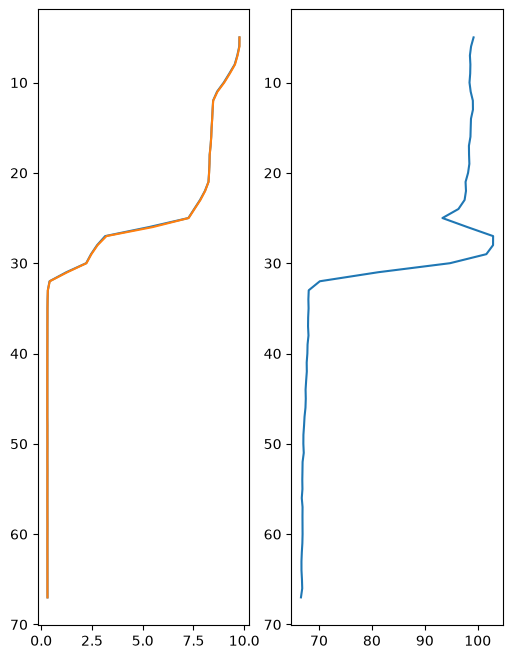

In [149]:
fig, ax = plt.subplots(1,2,figsize=(6, 8))

ax[0].plot(ctd_subset['T_28 (degree_C)'],ctd_subset['pressure'])
ax[0].plot(ctd_subset['T2_35 (degree_C)'],ctd_subset['pressure'])
ax[0].invert_yaxis()

ax[1].plot(ctd_subset['OST_62 (%)'],ctd_subset['pressure'])
ax[1].plot(rbr_subset['Dissolved O2 saturation'],
ax[1].invert_yaxis()


In [150]:
ctd_subset

,profile_id,latitude (degrees_north),longitude (degrees_east),time (UTC),pressure,S_42 (PSU),S_41 (PSU),Fch_906 (micrograms (ug) / l),T_28 (degree_C),T2_35 (degree_C),O_65 (um/kg),CTDOXY_4221 (um/kg),OST_62 (%),CTDOST_4220 (%),Trb_980 (NTU),PAR_905 (uEin m-2 s-1)
2871,ctd021,56.858667,164.03816,2026-08-12 06:45:05,5.0,31.1572,31.1641,0.1138,9.7659,9.7681,281.474,265.533,99.210,93.591,0.2935,NaN
2872,ctd021,56.858667,164.03816,2026-08-12 06:45:05,6.0,31.1568,31.1625,0.1073,9.7570,9.7679,280.192,264.753,98.737,93.315,0.3000,NaN
2873,ctd021,56.858667,164.03816,2026-08-12 06:45:05,7.0,31.1561,31.1625,0.1024,9.6608,9.6743,280.159,264.691,98.518,93.102,0.2836,NaN
2874,ctd021,56.858667,164.03816,2026-08-12 06:45:05,8.0,31.1538,31.1563,0.1148,9.5318,9.5464,281.218,265.397,98.607,93.088,0.2494,NaN
2875,ctd021,56.858667,164.03816,2026-08-12 06:45:05,9.0,31.1517,31.1575,0.1146,9.2676,9.2926,282.750,266.799,98.572,93.058,0.2561,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2929,ctd021,56.858667,164.03816,2026-08-12 06:45:05,63.0,31.8527,31.8626,0.9471,0.3089,0.3082,235.879,224.909,66.690,63.582,0.1526,NaN
2930,ctd021,56.858667,164.03816,2026-08-12 06:45:05,64.0,31.8526,31.8623,1.1045,0.3086,0.3083,235.897,225.156,66.694,63.652,0.1602,NaN
2931,ctd021,56.858667,164.03816,2026-08-12 06:45:05,65.0,31.8527,31.8625,1.0669,0.3095,0.3086,236.206,224.832,66.783,63.561,0.1583,NaN
2932,ctd021,56.858667,164.03816,2026-08-12 06:45:05,66.0,31.8524,31.8624,0.9485,0.3095,0.3085,236.390,224.990,66.835,63.605,0.1583,NaN


In [152]:
rbr_data.loc['2026-08-12 06']

,Temperature,Dissolved O2 concentration,Dissolved O2 saturation
Time,,,
2026-08-12 06:37:33.500,10.531799,278.496887,99.938713
2026-08-12 06:37:34.000,10.531799,278.496887,99.938713
2026-08-12 06:37:34.500,10.531500,278.491699,99.936211
2026-08-12 06:37:35.000,10.531500,278.491699,99.936211
2026-08-12 06:37:35.500,10.531099,278.707947,100.012939
...,...,...,...
2026-08-12 06:59:57.500,9.778299,282.718170,99.813614
2026-08-12 06:59:58.000,9.778299,282.718170,99.813614
2026-08-12 06:59:58.500,9.779400,283.082520,99.944641
